# Course 4 — Particle Filters

*My study notes in simple language. Few derivations — mainly ideas, key equations and Python demos.*

**Contents**
1. Bayesian recursion in integral form, and solving it on a grid
2. Monte-Carlo integration, importance sampling, weights
3. The particle filter (SIS) and resampling (SIR)
4. Application: indoor navigation with a particle filter

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(4)
plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True

---
## Why particle filters?
Kalman filters (linear, EKF, SPKF) describe the state with only a **mean and a covariance** — they assume the pdf is (roughly) Gaussian.
This fails when the true pdf is:
- **multi-modal** (several separate likely values — e.g. "I am in room A *or* room B"),
- strongly skewed, or bounded (e.g. walls, positivity constraints),
- produced by very nonlinear models or non-Gaussian noise.

A **particle filter (PF)** represents the whole pdf by a cloud of weighted samples ("particles"). With enough particles it can represent *any* shape.
Price: much more computation than a KF.

---
## 1. Bayesian recursion — the general solution

Model in probability form:
- **transition pdf** $f(x_k \mid x_{k-1})$ — from the state equation and process noise
- **likelihood** $f(z_k \mid x_k)$ — from the output equation and sensor noise

Two steps each time sample (same predict/correct idea as KF, but for the full pdf):

**Predict** (Chapman–Kolmogorov):
$$f(x_k \mid \mathbb Z_{k-1}) = \int f(x_k \mid x_{k-1})\, f(x_{k-1} \mid \mathbb Z_{k-1})\, dx_{k-1}$$

**Correct** (Bayes' rule):
$$f(x_k \mid \mathbb Z_k) = \frac{f(z_k \mid x_k)\, f(x_k \mid \mathbb Z_{k-1})}{f(z_k \mid \mathbb Z_{k-1})}$$
The denominator is just a normalising constant (so the pdf integrates to 1).

For linear-Gaussian systems this recursion gives exactly the KF. In general, the integrals have no closed form → approximate them numerically.

### Numerical integration on a grid
For low-dimensional states (1-D, 2-D) we can store the pdf at grid points and replace integrals by sums (rectangle/trapezoid rule).
**Problem:** the number of grid points grows exponentially with dimension ("curse of dimensionality") — impractical beyond ~3 states. That motivates Monte-Carlo (particles).

### Example problem used in this notebook
A point moves around a circle (centre $(x_0, y_0) = (500, 500)$ m, radius $r = 200$ m).
State = its angle $\phi_k$ on the circle, which advances about $\omega = 2^\circ$ per sample plus noise:
$$\phi_k = \phi_{k-1} + \omega + w_{k-1}$$
A sensor at the origin measures only the **bearing** to the point:
$$\theta_k = \arctan\frac{r\sin\phi_k + y_0}{r\cos\phi_k + x_0} + v_k$$
**Why this is hard for a KF:** from the origin, a line of sight usually crosses the circle **twice** → one bearing fits two different angles → the posterior is **bimodal**.

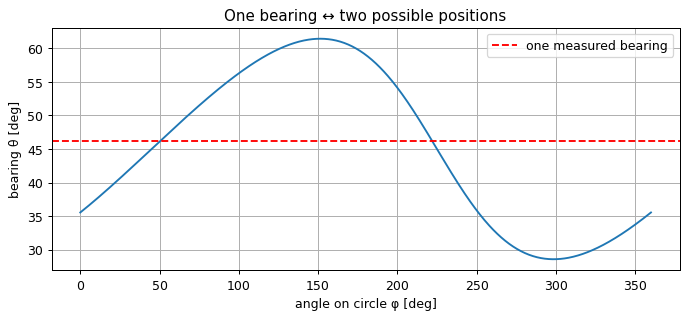

In [2]:
x0c, y0c, rad = 500.0, 500.0, 200.0
omega = np.deg2rad(2.0)
sig_w, sig_v = np.deg2rad(2.0), np.deg2rad(2.0)
phi0_mean = np.deg2rad(50.0)      # initially we have NO idea where the point is:
                                   # the prior is uniform over the whole circle

def bearing(phi):
    return np.arctan2(rad*np.sin(phi) + y0c, rad*np.cos(phi) + x0c)

def wrap(a):                       # wrap angle to [-pi, pi)
    return (a + np.pi) % (2*np.pi) - np.pi

N = 100
phi = np.zeros(N); zb = np.zeros(N)
phi[0] = phi0_mean
for k in range(N):
    if k > 0:
        phi[k] = phi[k-1] + omega + sig_w*np.random.randn()
    zb[k] = bearing(phi[k]) + sig_v*np.random.randn()

# show the ambiguity: bearing as a function of the angle on the circle
g = np.linspace(0, 2*np.pi, 721)
plt.plot(np.rad2deg(g), np.rad2deg(bearing(g)))
plt.axhline(np.rad2deg(zb[0]), color='r', ls='--', label="one measured bearing")
plt.xlabel("angle on circle φ [deg]"); plt.ylabel("bearing θ [deg]")
plt.title("One bearing ↔ two possible positions"); plt.legend(); plt.show()

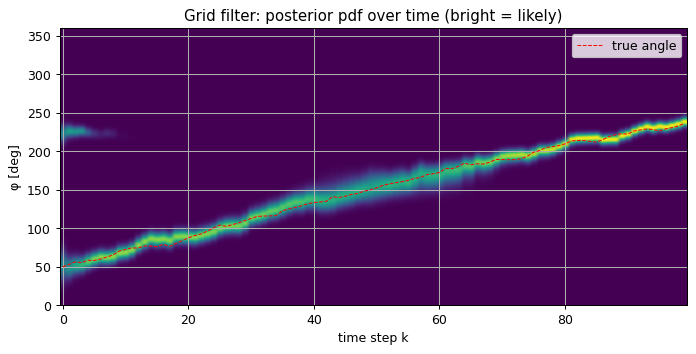

In [3]:
# ---- Grid-based Bayesian filter (1-D state -> a grid works fine)
G = 720
grid = np.linspace(0, 2*np.pi, G, endpoint=False); dg = grid[1] - grid[0]

def gauss(x, s):
    return np.exp(-0.5*(x/s)**2)/(np.sqrt(2*np.pi)*s)

# transition matrix T[i, j] = f(phi_i | phi_j)  (wrapped Gaussian)
T = gauss(wrap(grid[:, None] - grid[None, :] - omega), sig_w)

pdf = np.ones(G)/(2*np.pi)                                 # uniform prior
pdf_store = np.zeros((N, G))
for k in range(N):
    if k > 0:
        pdf = T @ pdf * dg                                   # predict (integral -> sum)
    pdf = pdf * gauss(wrap(zb[k] - bearing(grid)), sig_v)    # correct (Bayes)
    pdf /= pdf.sum()*dg                                      # normalise
    pdf_store[k] = pdf

plt.figure(figsize=(9, 4))
plt.imshow(pdf_store.T**0.5, origin='lower', aspect='auto', extent=[-0.5, N-0.5, 0, 360], cmap='viridis')
plt.plot(np.rad2deg(phi % (2*np.pi)), 'r--', lw=0.8, label="true angle")
plt.xlabel("time step k"); plt.ylabel("φ [deg]"); plt.legend()
plt.title("Grid filter: posterior pdf over time (bright = likely)"); plt.show()

At the start the posterior has **two bright bands** — the bimodality a Kalman filter cannot represent. Because the point keeps moving at a known rate, the bearing of the wrong candidate soon changes differently from the measured one, and that mode dies out. After that, the pdf is a single narrow peak following the truth.

---
## 2. Monte-Carlo integration and importance sampling

### Monte-Carlo idea
To compute an expectation $\mathbb E[g(x)] = \int g(x) f(x)\,dx$: draw samples $x^{(i)} \sim f(x)$ and average:
$$\mathbb E[g(x)] \approx \frac1{N_p}\sum_{i=1}^{N_p} g(x^{(i)})$$
Error shrinks like $1/\sqrt{N_p}$ — **independent of dimension**. That is why it beats grids in high dimensions.

### Importance sampling
Often we **cannot** sample from $f(x)$ directly. Then sample from an easier **importance density** $q(x)$ and correct with weights:
$$\mathbb E[g(x)] \approx \sum_i \tilde w^{(i)} g(x^{(i)}),\qquad w^{(i)} = \frac{f(x^{(i)})}{q(x^{(i)})}$$
- $q$ should cover everywhere $f$ is non-zero and ideally look similar to $f$ → weights are even, few samples wasted.

### Weight normalisation
If $f$ is only known up to a constant (typical in Bayes: we know numerator, not the normaliser), normalise:
$$\tilde w^{(i)} = \frac{w^{(i)}}{\sum_j w^{(j)}}$$
The unknown constant cancels.

### Particles as a sum of impulses
The pdf is represented as
$$f(x) \approx \sum_i \tilde w^{(i)}\,\delta(x - x^{(i)})$$
where $\delta$ is the Dirac impulse (area 1, zero width). Integrals against impulses become simple sums. To **visualise** such a pdf: a weighted histogram, or a smoothed version (kernel density — put a small Gaussian on each particle).

true mean       : 0.450
importance est. : 0.426
effective number of samples: 2568 of 5000


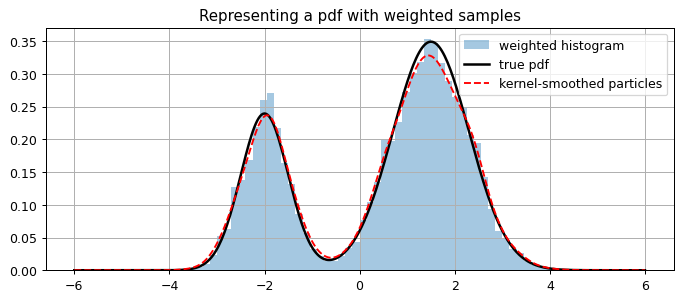

In [4]:
# Target: a bimodal pdf that we can evaluate but not easily sample
f_target = lambda x: 0.3*gauss(x+2, 0.5) + 0.7*gauss(x-1.5, 0.8)

# Importance density: a wide Gaussian
q_std = 3.0
xs = q_std*np.random.randn(5000)
w = f_target(xs) / gauss(xs, q_std)
w_norm = w / w.sum()

true_mean = 0.3*(-2) + 0.7*1.5
print("true mean       : %.3f" % true_mean)
print("importance est. : %.3f" % np.sum(w_norm*xs))
print("effective number of samples: %.0f of %d" % (1/np.sum(w_norm**2), len(xs)))

xx = np.linspace(-6, 6, 400)
kde = sum(wi*gauss(xx - xi, 0.2) for wi, xi in zip(w_norm, xs))   # smoothed particle pdf
plt.hist(xs, bins=80, weights=w_norm/(12/80), alpha=0.4, range=(-6, 6), label="weighted histogram")
plt.plot(xx, f_target(xx), 'k', lw=2, label="true pdf")
plt.plot(xx, kde, 'r--', label="kernel-smoothed particles")
plt.legend(); plt.title("Representing a pdf with weighted samples"); plt.show()

---
## 3. The particle filter

### Sequential importance sampling (SIS)
Apply importance sampling **recursively**. Each particle $i$ keeps a state $x_k^{(i)}$ and a weight $w_k^{(i)}$.
1. **Draw** new particles from the importance density: $x_k^{(i)} \sim q(x_k \mid x_{k-1}^{(i)}, z_k)$
2. **Update weights**:
$$w_k^{(i)} = w_{k-1}^{(i)}\;\frac{f(z_k \mid x_k^{(i)})\, f(x_k^{(i)} \mid x_{k-1}^{(i)})}{q(x_k^{(i)} \mid x_{k-1}^{(i)}, z_k)}$$
3. **Normalise** weights.
4. **Estimate**: e.g. $\hat x_k = \sum_i \tilde w_k^{(i)} x_k^{(i)}$ (or the most likely particle / a credible interval).

**Easiest choice of $q$:** the transition pdf itself, $q = f(x_k \mid x_{k-1})$ ("bootstrap" filter). Then things cancel and simply
$$w_k^{(i)} = w_{k-1}^{(i)}\; f(z_k \mid x_k^{(i)})$$
i.e. propagate each particle through the state equation with random noise, then weight it by how well it explains the measurement.

### The problem: degeneracy
After a few steps almost all weight sits on **one** particle; the rest are wasted.
Measure it with the **effective sample size**:
$$\hat N_{\text{eff}} = \frac{1}{\sum_i (\tilde w^{(i)})^2}$$
($N_p$ = perfect, 1 = fully degenerate).

### Resampling (→ SIR filter)
When $\hat N_{\text{eff}}$ drops below a threshold (e.g. $N_p/2$): draw $N_p$ new particles from the current set **with probability equal to their weights**, then set all weights to $1/N_p$.
Good particles get copied, bad ones disappear. (Common method: systematic resampling — one random number, $N_p$ evenly spaced pointers into the cumulative weights.)
Side effect: loss of diversity ("sample impoverishment") — the process noise in the next prediction spreads the copies out again.

RMS error (steps 30-100)  SIS: 5.6°   SIR: 3.4°


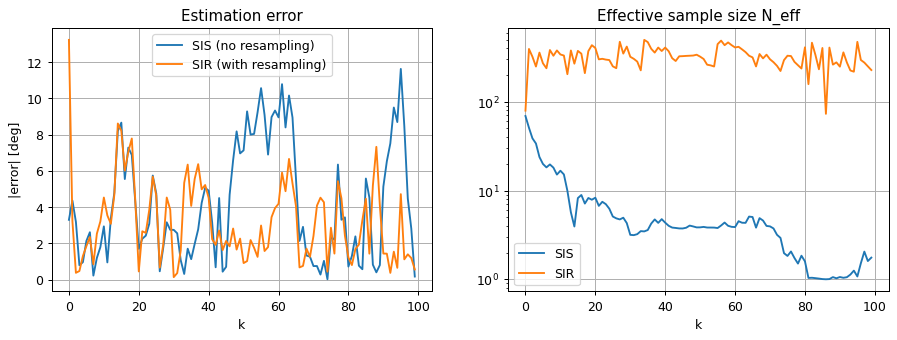

In [5]:
def systematic_resample(weights):
    Np = len(weights)
    positions = (np.random.rand() + np.arange(Np)) / Np
    cs = np.cumsum(weights); cs[-1] = 1.0
    return np.searchsorted(cs, positions)

def circ_mean(angles, w):
    return np.arctan2(np.sum(w*np.sin(angles)), np.sum(w*np.cos(angles)))

def particle_filter(zb, Np=500, resample=True):
    p = np.random.uniform(0, 2*np.pi, Np)                 # initial particles from the (uniform) prior
    w = np.ones(Np)/Np
    est, neff, cloud = np.zeros(N), np.zeros(N), np.zeros((N, Np))
    for k in range(N):
        if k > 0:
            p = p + omega + sig_w*np.random.randn(Np)       # draw from f(x_k | x_{k-1})
        w = w * gauss(wrap(zb[k] - bearing(p)), sig_v)      # weight by likelihood
        w = w / w.sum() if w.sum() > 0 else np.ones(Np)/Np
        est[k] = circ_mean(p, w); neff[k] = 1/np.sum(w**2); cloud[k] = p
        if resample and neff[k] < Np/2:
            idx = systematic_resample(w); p = p[idx]; w = np.ones(Np)/Np
    return est, neff, cloud

est_sis, neff_sis, _ = particle_filter(zb, resample=False)
est_sir, neff_sir, cloud = particle_filter(zb, resample=True)

err = lambda e: np.rad2deg(np.abs(wrap(e - phi)))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(err(est_sis), label="SIS (no resampling)"); ax[0].plot(err(est_sir), label="SIR (with resampling)")
ax[0].set_ylabel("|error| [deg]"); ax[0].set_xlabel("k"); ax[0].legend(); ax[0].set_title("Estimation error")
ax[1].semilogy(neff_sis, label="SIS"); ax[1].semilogy(neff_sir, label="SIR")
ax[1].set_xlabel("k"); ax[1].set_title("Effective sample size N_eff"); ax[1].legend(); plt.show()
print("RMS error (steps 30-100)  SIS: %.1f°   SIR: %.1f°" % (np.sqrt(np.mean(err(est_sis)[30:]**2)), np.sqrt(np.mean(err(est_sir)[30:]**2))))

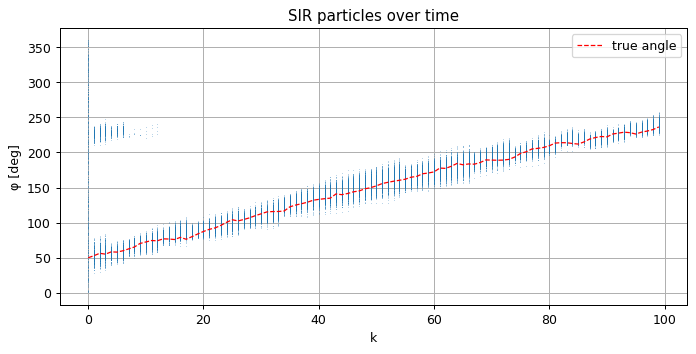

In [6]:
# Look at the particle cloud of the SIR filter: two clusters early on, one later
kk = np.repeat(np.arange(N), cloud.shape[1])
plt.figure(figsize=(9, 4))
plt.plot(kk, np.rad2deg(cloud.ravel() % (2*np.pi)), ',', alpha=0.3, color='C0')
plt.plot(np.rad2deg(phi % (2*np.pi)), 'r--', lw=1, label="true angle")
plt.xlabel("k"); plt.ylabel("φ [deg]"); plt.legend(); plt.title("SIR particles over time"); plt.show()

**What to notice**
- Without resampling, $N_{\text{eff}}$ collapses to ~1 within a few steps and the SIS estimate gets stuck.
- With resampling, the particles follow the truth; early on they split into **two clusters** (the two positions consistent with the bearing), which a KF could never represent.
- Note: the weighted **mean** of a bimodal cloud can lie between the two modes (where the point is *not*) — for multi-modal posteriors it is often better to report the most likely cluster.

---
## 4. Application: indoor navigation

### Navigation basics
- **Relative sensors** (IMU, wheel odometry): measure speed/acceleration/turn rate. Integrating them = **dead reckoning** → errors grow without bound (drift).
- **Absolute sensors** (GPS, beacons, maps): fix the absolute position, but are noisy/intermittent.
- Fuse both: relative sensors drive the **prediction**, absolute sensors the **correction**. Outdoors, GPS + IMU with an EKF works well.

### Why indoors is different
GPS signals are too weak indoors and ~3 m accuracy is not enough. Alternatives:
- **Trilateration:** distances to known points (e.g. from radio time-of-flight or signal strength).
- **Triangulation:** angles to known points (e.g. antenna arrays).
- **Beacons** (UWB, WiFi, BLE, ZigBee) at surveyed positions, or **map matching** with LIDAR/ultrasound/radar (→ SLAM if the map is also learned).

With a moving platform and a PF, even **one or two** beacons can be enough — motion + map constraints resolve the ambiguity over time.

### Signal-strength (RSSI) measurement model
Path loss in dB between transmitter and receiver:
$$\text{Loss} = L_{1\text{m}} + 20\log_{10}(d) + N_{\text{walls}}\cdot L_{\text{wall}} + S,\qquad S \sim \mathcal N(0, \sigma_{\text{ln}}^2)$$
(free-space loss + wall losses + random "log-normal shadowing"). Since $S$ is additive Gaussian, the likelihood $f(z_k \mid x_k^{(i)})$ is Gaussian around the predicted loss for each particle.

### Motion model
$$\begin{bmatrix}\xi_{k+1}\\ \eta_{k+1}\end{bmatrix} = \begin{bmatrix}\xi_{k}\\ \eta_{k}\end{bmatrix} + \Delta t \begin{bmatrix}s_k\cos\theta_k\\ s_k\sin\theta_k\end{bmatrix}$$
with measured speed $s^m = s + w^s$ and heading $\theta^m = \theta + w^\theta$. For the bootstrap PF we simply propagate each particle with its own random sample of speed and heading noise — no need to write down $f(x_k \mid x_{k-1})$ in closed form.

**Map constraint:** particles that leave the room get weight 0 — something very natural in a PF and awkward in a KF.

### Simplified demo (my version)
10 m × 10 m room, two beacons at (1.5, 1.5) and (7.5, 7.5), no internal walls. The vehicle drives a loop. Particles start **uniformly over the whole room** (we have no idea where we are — "global localisation").

In [7]:
W = 10.0
beacons = np.array([[1.5, 1.5], [7.5, 7.5]])
L1m, sig_ln = 40.0, 2.0                 # loss at 1 m [dB], shadowing std [dB]
sig_s, sig_th = 0.05, np.deg2rad(5.0)   # odometry noise: speed [m/s], heading [rad]
dtn = 0.5

def path_loss(pos):                     # pos: (..., 2) -> loss to each beacon (..., 2)
    d = np.linalg.norm(pos[..., None, :] - beacons, axis=-1)
    return L1m + 20*np.log10(np.maximum(d, 0.1))

# ---- true path: a rounded loop through the room
waypts = np.array([[2, 2], [8, 2], [8, 8], [2, 8]]*3 + [[2, 2]])
speed = 0.6
pos = [waypts[0].astype(float)]; heading = []
for a, b in zip(waypts[:-1], waypts[1:]):
    n_steps = int(np.linalg.norm(b - a)/(speed*dtn))
    th = np.arctan2(*(b - a)[::-1])
    for _ in range(n_steps):
        heading.append(th); pos.append(pos[-1] + dtn*speed*np.array([np.cos(th), np.sin(th)]))
pos = np.array(pos[:-1]); heading = np.array(heading); K = len(heading)

# odometry readings: random noise PLUS small systematic errors (scale error, gyro bias)
s_meas = 1.05*speed + sig_s*np.random.randn(K)
th_meas = heading + np.deg2rad(3.0) + sig_th*np.random.randn(K)
rssi = path_loss(pos) + sig_ln*np.random.randn(K, 2)          # beacon readings
print("steps:", K)

steps: 240


mean error after convergence (k>40): PF 0.28 m, dead reckoning 0.55 m


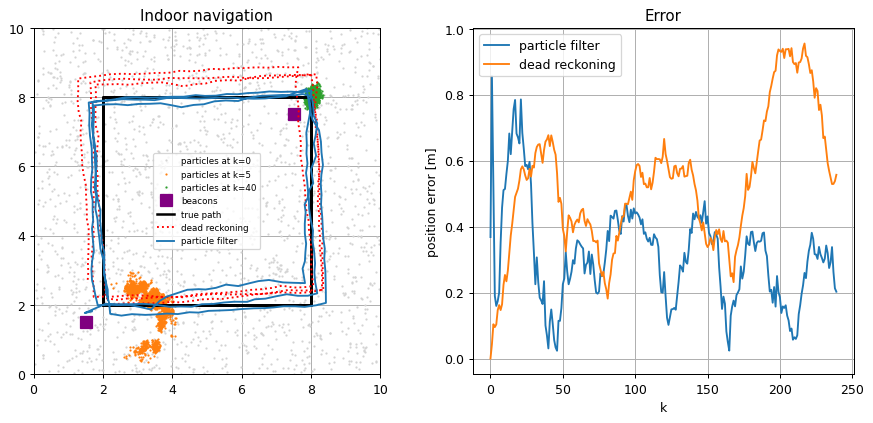

In [8]:
def pf_navigate(Np=2000):
    P = np.random.uniform(0, W, (Np, 2))                     # uniform over room
    w = np.ones(Np)/Np; est = np.zeros((K, 2)); snaps = {}
    for k in range(K):
        # correct: likelihood of both RSSI readings, and the map constraint
        pred = path_loss(P)
        w = w * np.exp(-0.5*np.sum(((rssi[k] - pred)/sig_ln)**2, axis=1))
        inside = np.all((P >= 0) & (P <= W), axis=1); w = w*inside
        w = w/w.sum() if w.sum() > 0 else np.ones(Np)/Np
        est[k] = w @ P
        if k in (0, 5, 40): snaps[k] = P.copy()
        if 1/np.sum(w**2) < Np/2:
            P = P[systematic_resample(w)]; w = np.ones(Np)/Np
        # predict: move each particle with its own noisy copy of the odometry
        s = s_meas[k] - sig_s*np.random.randn(Np)
        th = th_meas[k] - sig_th*np.random.randn(Np)
        P = P + dtn*np.column_stack([s*np.cos(th), s*np.sin(th)])
    return est, snaps

est_pf, snaps = pf_navigate()

# dead reckoning alone (knowing the true start!) for comparison
dr = np.zeros((K, 2)); dr[0] = pos[0]
for k in range(1, K):
    dr[k] = dr[k-1] + dtn*s_meas[k-1]*np.array([np.cos(th_meas[k-1]), np.sin(th_meas[k-1])])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for k, c in zip(snaps, ['lightgray', 'C1', 'C2']):
    ax[0].plot(snaps[k][:, 0], snaps[k][:, 1], '.', ms=1.5, color=c, label=f"particles at k={k}")
ax[0].plot(*beacons.T, 's', color='purple', ms=10, label="beacons")
ax[0].plot(pos[:, 0], pos[:, 1], 'k', lw=2, label="true path")
ax[0].plot(dr[:, 0], dr[:, 1], 'r:', lw=1.5, label="dead reckoning")
ax[0].plot(est_pf[:, 0], est_pf[:, 1], 'C0', lw=1.5, label="particle filter")
ax[0].set_xlim(0, W); ax[0].set_ylim(0, W); ax[0].set_aspect('equal'); ax[0].legend(fontsize=7, loc="center")
ax[0].set_title("Indoor navigation")
e_pf = np.linalg.norm(est_pf - pos, axis=1); e_dr = np.linalg.norm(dr - pos, axis=1)
ax[1].plot(e_pf, label="particle filter"); ax[1].plot(e_dr, label="dead reckoning")
ax[1].set_xlabel("k"); ax[1].set_ylabel("position error [m]"); ax[1].legend(); ax[1].set_title("Error")
plt.show()
print("mean error after convergence (k>40): PF %.2f m, dead reckoning %.2f m" % (e_pf[40:].mean(), e_dr[40:].mean()))

**What to notice**
- At the start the particles fill the room (no idea where we are). The first RSSI readings shrink them to rings around the beacons; motion then quickly collapses them to one cluster.
- Dead reckoning starts at the *correct* position but drifts away (small speed-scale and gyro-bias errors accumulate); the PF starts with no knowledge but its error stays bounded thanks to the beacons.

### Possible extensions (as discussed in the course)
- Walls inside the room: count wall crossings between particle and beacon → extra loss; forbid particles from crossing walls.
- Better importance densities (e.g. use sigma points or a local linearisation to build $q$ that already includes the new measurement).
- More sensors: LIDAR map matching, UWB ranging, multipath fading models.

---
## Summary
- The **Bayesian recursion** (predict with an integral, correct with Bayes' rule) is the general solution; KF is a special case.
- Grids solve it in low dimensions; **Monte-Carlo** sampling scales much better.
- **Importance sampling** lets us sample from an easy density and fix things up with weights.
- **Particle filter (SIS):** propagate particles, weight by likelihood, normalise. Simplest version: bootstrap filter with $q$ = transition pdf.
- **Degeneracy** is the main problem → monitor $N_{\text{eff}}$ and **resample** (SIR).
- PFs shine for **multi-modal**, constrained, and strongly nonlinear problems such as indoor navigation — at a higher computational cost.